# **MODELOS DE CLUSTERING: ESPECIES DE PINGÜINOS**

El siguiente dataset contempla información de los pingüinos (pico, aleta, corporal y sexo). El objetivo de este NoteBook, es implementar diferentes modelos de clustering para comprender el comportamiento en cada uno de ellos.

Las librerias a incorporar permite la manipulación de datos, aplicar los modelos de cluster y graficar la data/resultados.

In [1]:
import pandas as pd
import numpy as np

import matplotlib.pyplot as plt
from matplotlib.colors import Normalize
from matplotlib.cm import ScalarMappable

from sklearn.cluster import KMeans, DBSCAN, MiniBatchKMeans

# EXTRACIÓN DE DATOS

Los datos fue exportado del dataset de Kaggle denominado [**Clustering Penguins Species**](https://www.kaggle.com/datasets/youssefaboelwafa/clustering-penguins-species). 

Con Pandas, se hace la lectura de la data indicando la ubicacion del archivo (que se encuentra en el directorio del proyecto)

In [2]:
data = pd.read_csv(
    filepath_or_buffer='data/penguins.csv', 
    encoding="UTF-8"
)

data

,culmen_length_mm,culmen_depth_mm,flipper_length_mm,body_mass_g,sex
0,39.1,18.7,181.0,3750.0,MALE
1,39.5,17.4,186.0,3800.0,FEMALE
2,40.3,18.0,195.0,3250.0,FEMALE
3,NaN,NaN,NaN,NaN,NaN
4,36.7,19.3,193.0,3450.0,FEMALE
...,...,...,...,...,...
339,NaN,NaN,NaN,NaN,NaN
340,46.8,14.3,215.0,4850.0,FEMALE
341,50.4,15.7,222.0,5750.0,MALE
342,45.2,14.8,212.0,5200.0,FEMALE


# LIMPIEZA DE DATOS

- Se hace el *dropna* para eliminar los NaN en todas las columnas del dataset
- Se renombra las columnas traduciendo sus nombres a español, con tal de entender el tipo de datos que se maneja.

In [3]:
data = data.dropna()

data = data.rename(
    columns={
        'culmen_length_mm': 'largo_pico',
        'culmen_depth_mm': 'grosor_pico',
        'flipper_length_mm': 'largo_aleta',
        'body_mass_g': 'masa_corporal',
        'sex': 'sexo'
    }
)

# Modelos de Clustering

## K-MEANS
---

Este modelo tiene por objetivo agrupar los pingüinos buscando similitudes en sus caracteristicas físicas, en este ejemplo práctico sera entre la longitud (o largo) y el grosor del pico. El rol de cumple un centroide es ubicarse en un grupo de datos basado en el promedio.

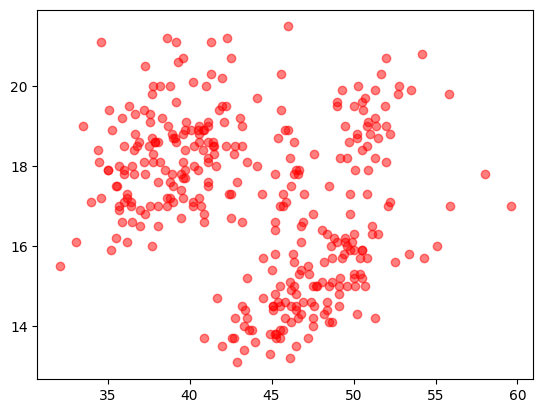

In [4]:
x = data['largo_pico']
y = data['grosor_pico']

XY = np.column_stack((x,y))

graph = plt.scatter(x,y, marker='o', c='red', alpha=0.5)
graph

Se dispone 3 modos de KMEANS:
* *k-means++*: los centroides se distribuye en la gráfica lo más disperso posible y ubicarse en la mejor forma de representar la agrupación de datos.

* *random*: los centroides se instalan aleatoriamente sin regulación o considerando en la distribución de datos.

* *mini-batch*: los datos son divididos en pequeñas muestras, luego se realizan varias iteraciones para actualizar la ubicación de los centroides

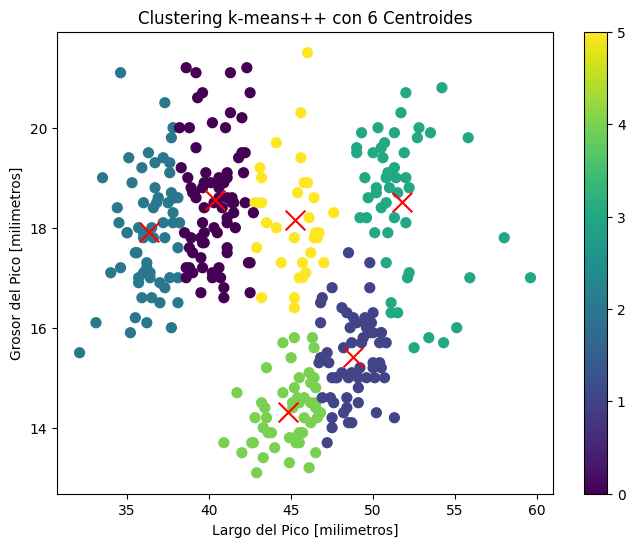

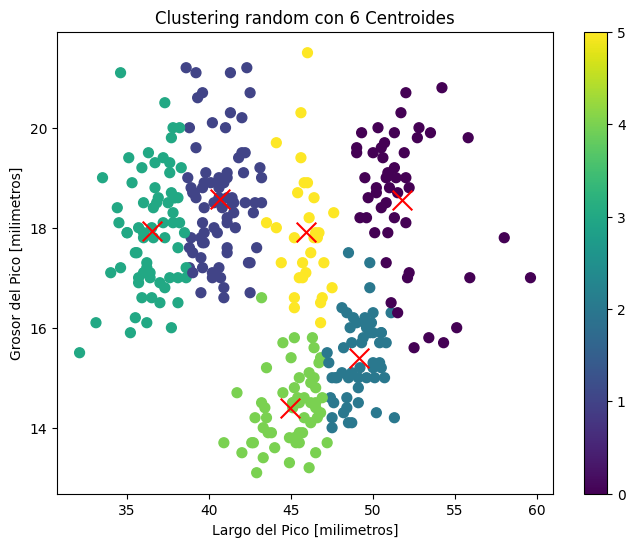

In [5]:
num_clust = 6

for mode in ['k-means++', 'random']:
    model = KMeans(init=mode, n_clusters=num_clust, random_state=42)
    model.fit(XY)
    
    label = model.labels_
    centroid = model.cluster_centers_

    plt.subplots(figsize=(8,6))

    plt.scatter(XY[:, 0], XY[:, 1], c=label, s=50, cmap='viridis')
    plt.colorbar()
    plt.scatter(centroid[:, 0], centroid[:, 1], marker='x', s=200, c='red')

    plt.xlabel('Largo del Pico [milimetros]')
    plt.ylabel('Grosor del Pico [milimetros]')
    plt.title(f'Clustering {mode} con {num_clust} Centroides')

plt.show()

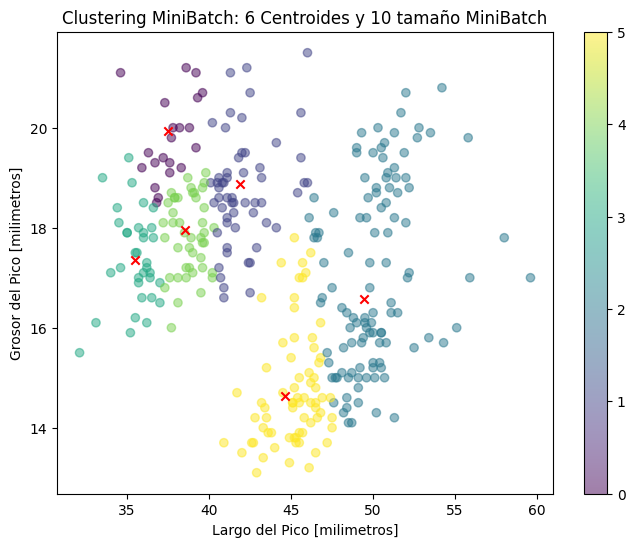

In [6]:
num_batch = 10

model = MiniBatchKMeans(n_clusters=num_clust, batch_size=num_batch, random_state=42)
model.fit(XY)

label = model.predict(XY)
centroid = model.cluster_centers_

plt.subplots(figsize=(8,6))

plt.scatter(XY[:, 0], XY[:, 1], c=label, alpha=0.5, cmap='viridis')
plt.colorbar()
plt.scatter(centroid[:, 0], centroid[:, 1], marker='x', c='red')

plt.xlabel('Largo del Pico [milimetros]')
plt.ylabel('Grosor del Pico [milimetros]')
plt.title(f'Clustering MiniBatch: {num_clust} Centroides y {num_batch} tamaño MiniBatch')

plt.show()

## DBSCAN
---

A diferencia del *K-mEANS*, *DBSCAN* agrupa los datos en funcion de densidad en el espacio, se trabajara en un entorno de 2 dimensiones:
- El largo del Pico (eje X)
- El grosor del Pico (eje Y)

En este algoritmo se define la distancia maxima de un cluster y un numero minimo de puntos para considerar un cluster como tal. Para ello se tiene 2 loop para probar 3 diferentes valores en Epsilon (distancia) y un minino de puntos.

Cada vez que el modelo realiza la evaluación genera un gráfico, donde cada punto del gráfico adquiere un color que representa un cluster. Tambien, se adjunta una barra de color que indica la cantidad de clusters que se formo y el color que representa.

Un punto a considerar, el valor -1 se tiene que interpretar que un o varios datos no pertenecen a un clusters y puede ser considerados como datos que generan ruido.

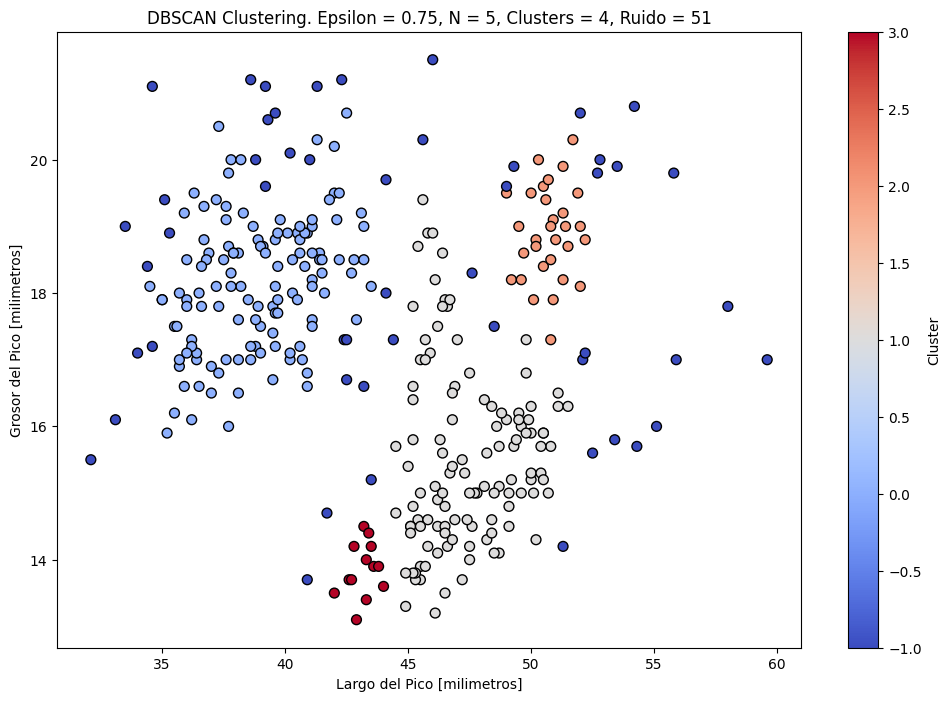

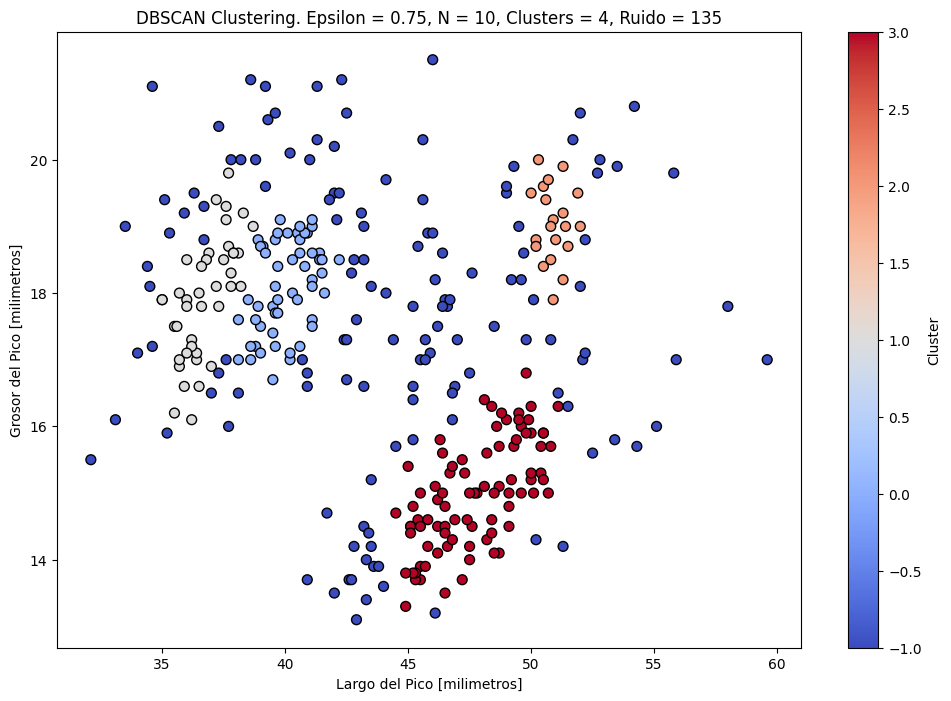

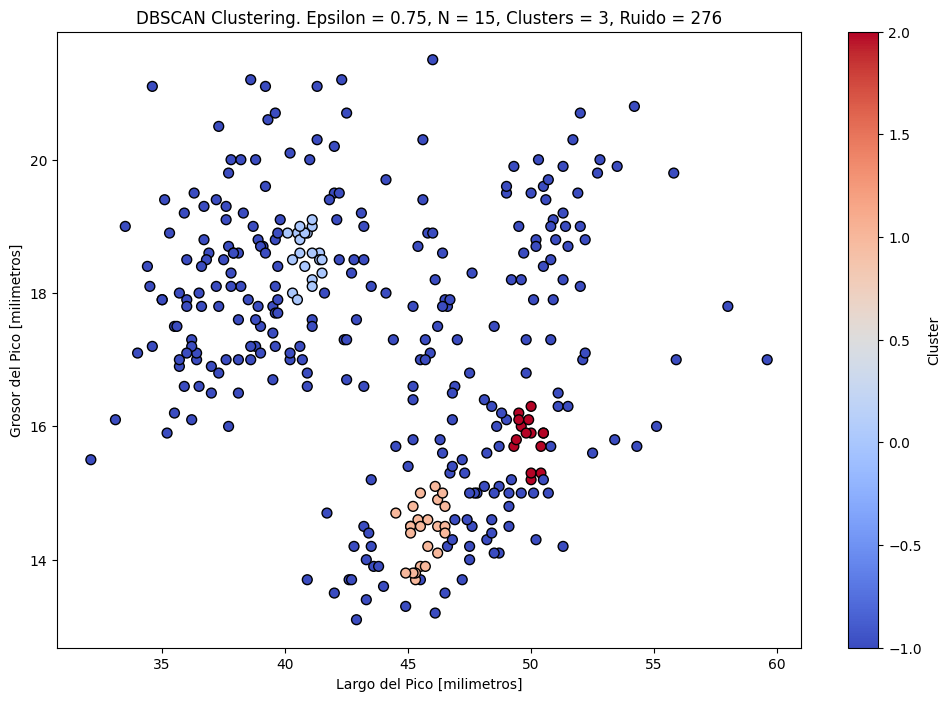

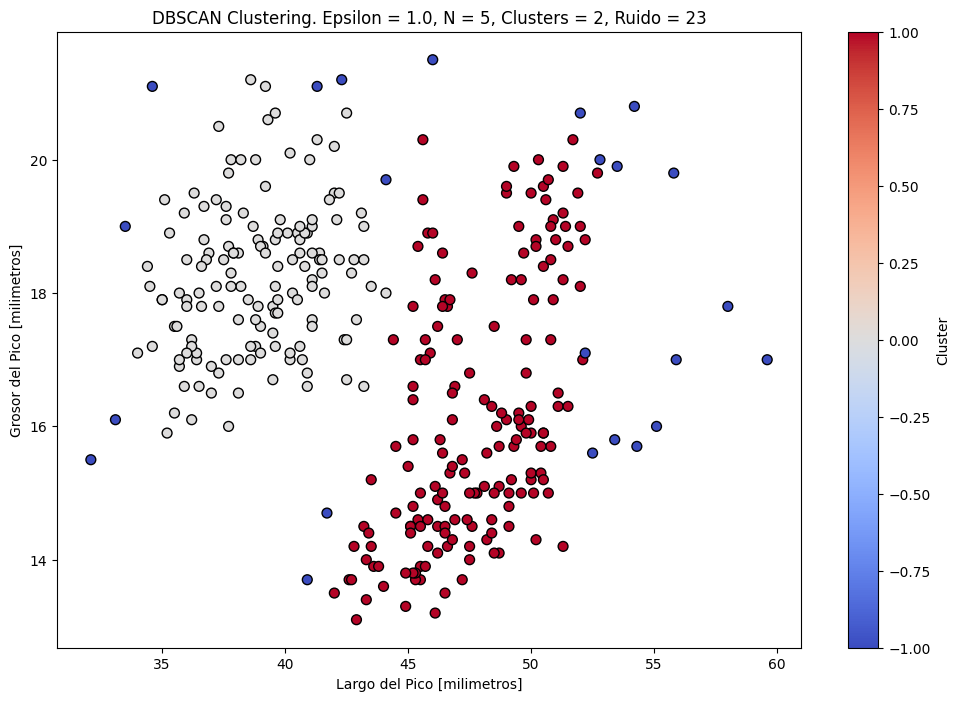

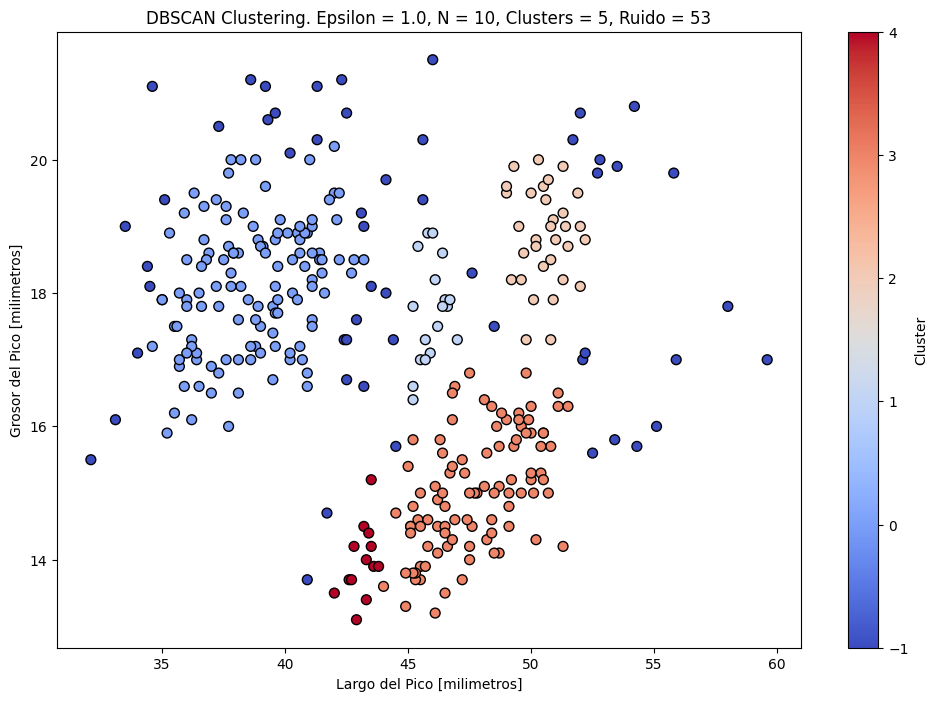

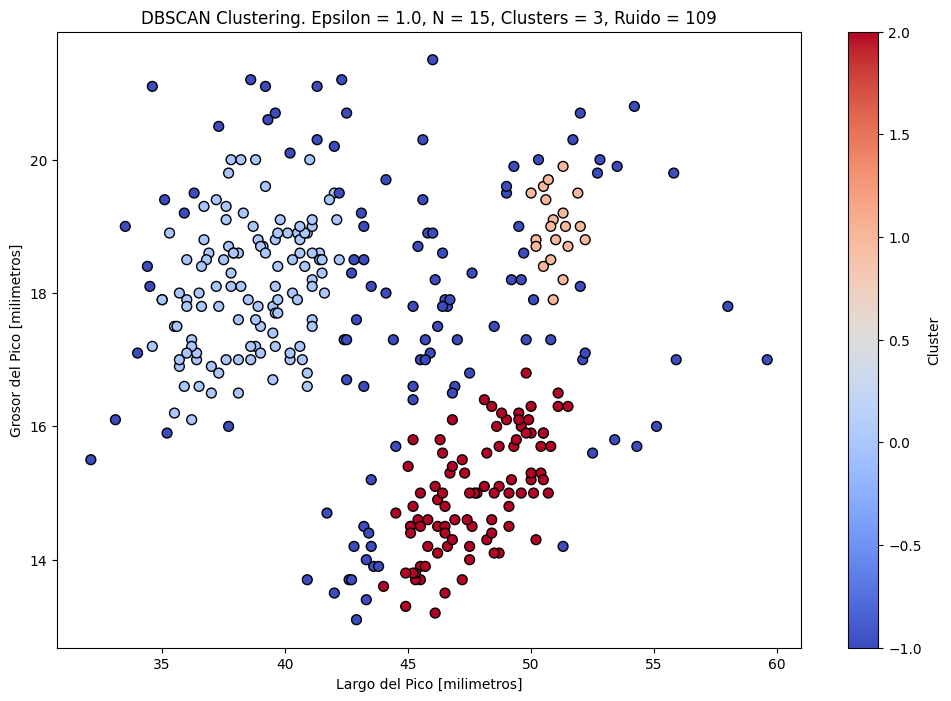

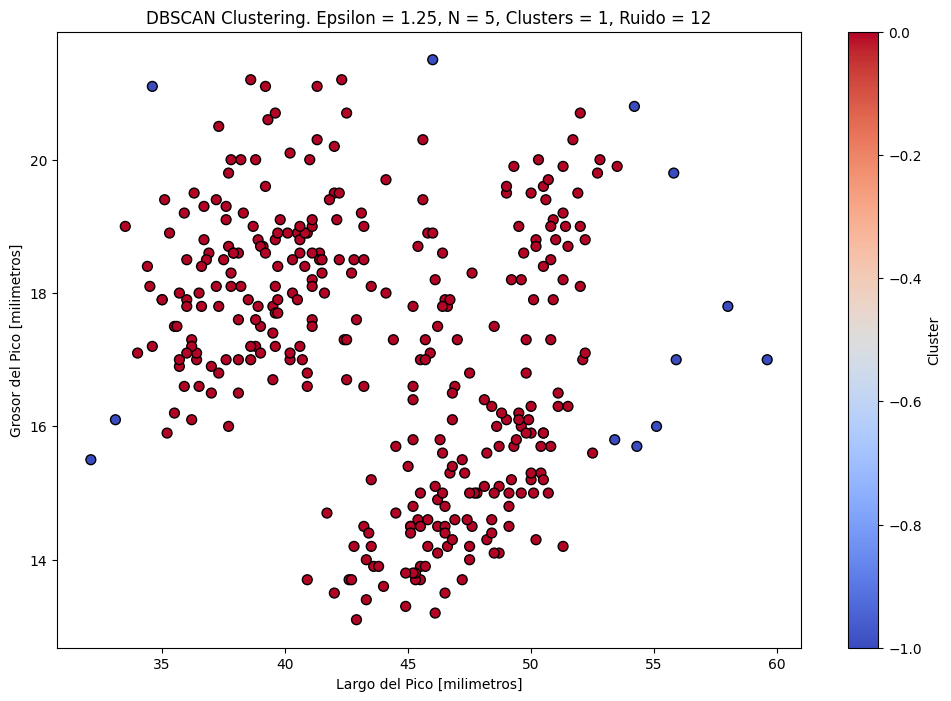

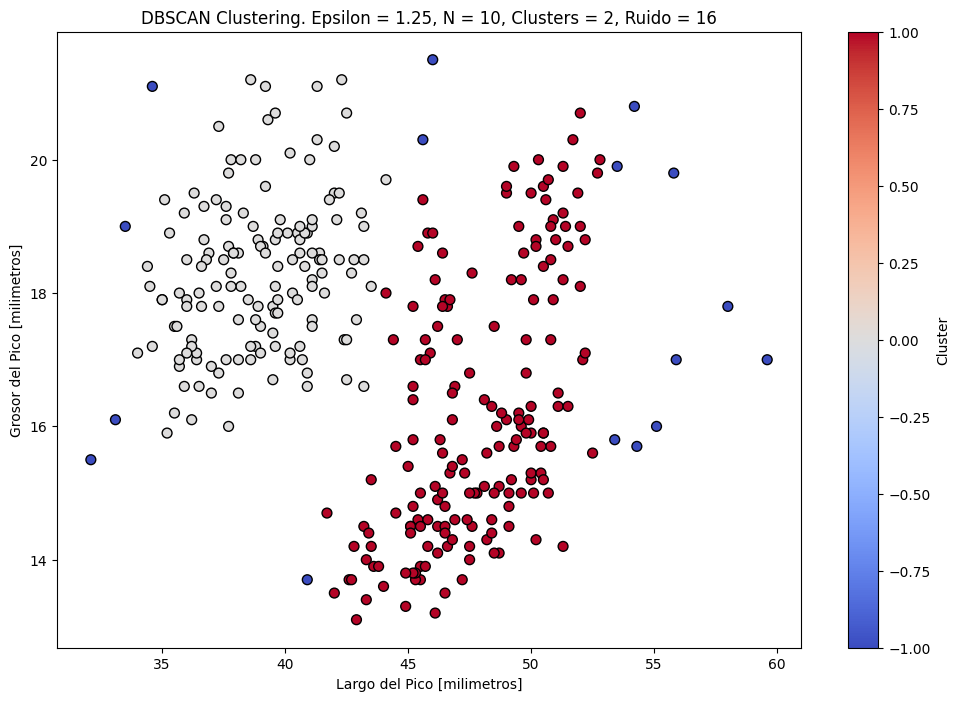

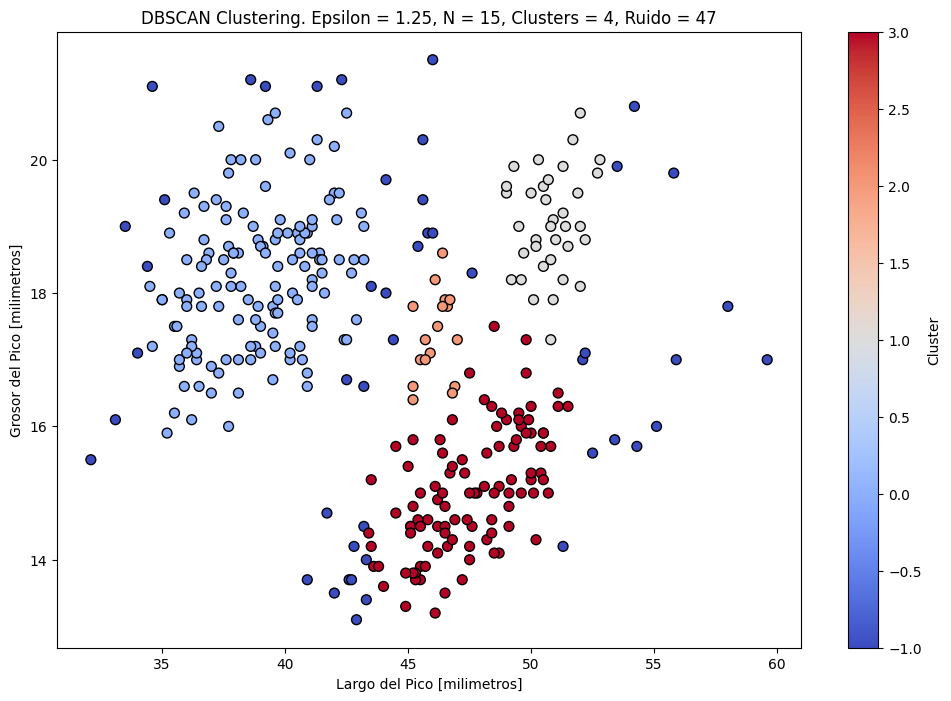

In [7]:
# 3 Valores de Distancia maxima
for i in [0.75, 1.0, 1.25]:

  # 3 Valores de Numeros minimos
  for j in [5, 10, 15]:

      # Aplicar DBSCAN
      dbscan = DBSCAN(eps=i, min_samples=j)
      clusters = dbscan.fit_predict(XY)

      n_clusters = len(set(clusters)) - (1 if -1 in clusters else 0)
      n_noise = list(clusters).count(-1)


      fig = plt.figure(figsize = (12,8))
      ax = fig.add_subplot(111)

      # Graficar los puntos en 3D con colores de acuerdo a los clusters
      ax.scatter(XY[:, 0], XY[:, 1], c=clusters, cmap='coolwarm', s=50, marker='o', edgecolor='k')

      # Configurar etiquetas y título
      ax.set_xlabel('Largo del Pico [milimetros]')
      ax.set_ylabel('Grosor del Pico [milimetros]')
      ax.set_title(f"DBSCAN Clustering. Epsilon = {str(i)}, N = {str(j)}, Clusters = {n_clusters}, Ruido = {n_noise}")

      norm = Normalize(vmin=clusters.min(), vmax=clusters.max())
      sm = ScalarMappable(cmap='coolwarm', norm=norm)
      sm.set_array([])

      # Agregar el colorbar a la figura
      cbar = plt.colorbar(sm, ax=ax)
      cbar.set_label('Cluster')

plt.show()